# Forest Fire Risk Prediction Using Random Forest


## Import the Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

print("Libraries imported successfully!")

Libraries imported successfully!


## Load Dataset

In [2]:
DATA_PATH = "forest_fire_dataset.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "forest_fire_dataset.csv was not found. "
        "Keep the CSV in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head().to_string(index=False))

Dataset loaded successfully!
Dataset shape: (500, 11)
 temperature  humidity  wind_speed  rain  ffmc  dmc    dc  isi  bui  fwi  fire
        33.2        82          15   0.2  77.2 14.3  26.0  2.2 14.8  1.2     0
        28.0        86          13   0.0  75.9 17.5  70.2  1.6 17.3  0.9     0
        34.9        61          14   0.0  85.6 29.2 144.8  2.2 36.3  0.4     1
        35.6        53          17   0.0  89.8 21.4  74.1  3.6 23.6  0.8     1
        24.6        57          16   0.0  75.1 30.7 119.4  1.1 30.5  1.0     0


## Check Dataset Information

In [3]:
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temperature  500 non-null    float64
 1   humidity     500 non-null    int64  
 2   wind_speed   500 non-null    int64  
 3   rain         500 non-null    float64
 4   ffmc         500 non-null    float64
 5   dmc          500 non-null    float64
 6   dc           500 non-null    float64
 7   isi          500 non-null    float64
 8   bui          500 non-null    float64
 9   fwi          500 non-null    float64
 10  fire         500 non-null    int64  
dtypes: float64(8), int64(3)
memory usage: 43.1 KB
None

Missing values:
temperature    0
humidity       0
wind_speed     0
rain           0
ffmc           0
dmc            0
dc             0
isi            0
bui            0
fwi            0
fire           0
dtype: int64


## Statistical Summary

In [4]:
print(df.describe().round(2).T[["mean", "min", "max"]])

              mean   min    max
temperature  31.95  22.2   42.0
humidity     71.46  37.0   90.0
wind_speed   15.49   7.0   24.0
rain          0.83   0.0   10.9
ffmc         76.53  50.2   94.5
dmc          25.84   0.7   55.1
dc           92.28   6.0  220.0
isi           1.24   0.0    6.0
bui          26.71   1.1   57.5
fwi           0.89   0.0    4.6
fire          0.58   0.0    1.0


## Visualize Fire / No Fire Distribution

fire
No Fire    210
Fire       290
Name: count, dtype: int64


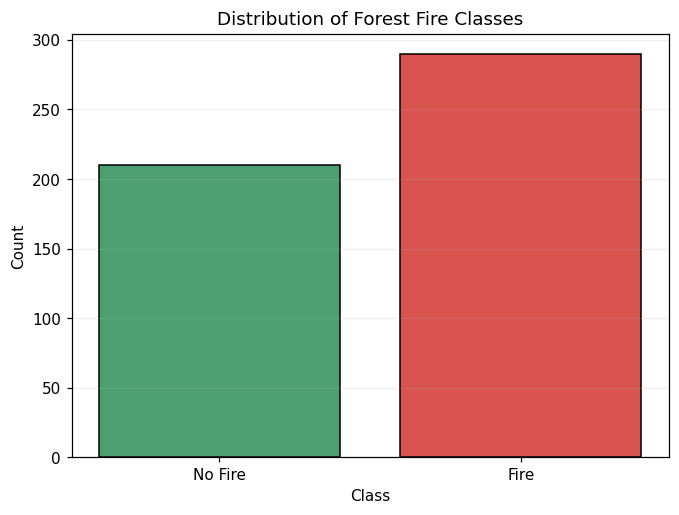

In [5]:
counts = df["fire"].value_counts().sort_index()
print(counts.rename({0: "No Fire", 1: "Fire"}))

plt.figure(figsize=(7, 5))
plt.bar(["No Fire", "Fire"], counts.values, color=["#4c9f70", "#d9534f"], edgecolor="black")
plt.title("Distribution of Forest Fire Classes")
plt.xlabel("Class")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.2)
plt.show()

## Correlation Analysis

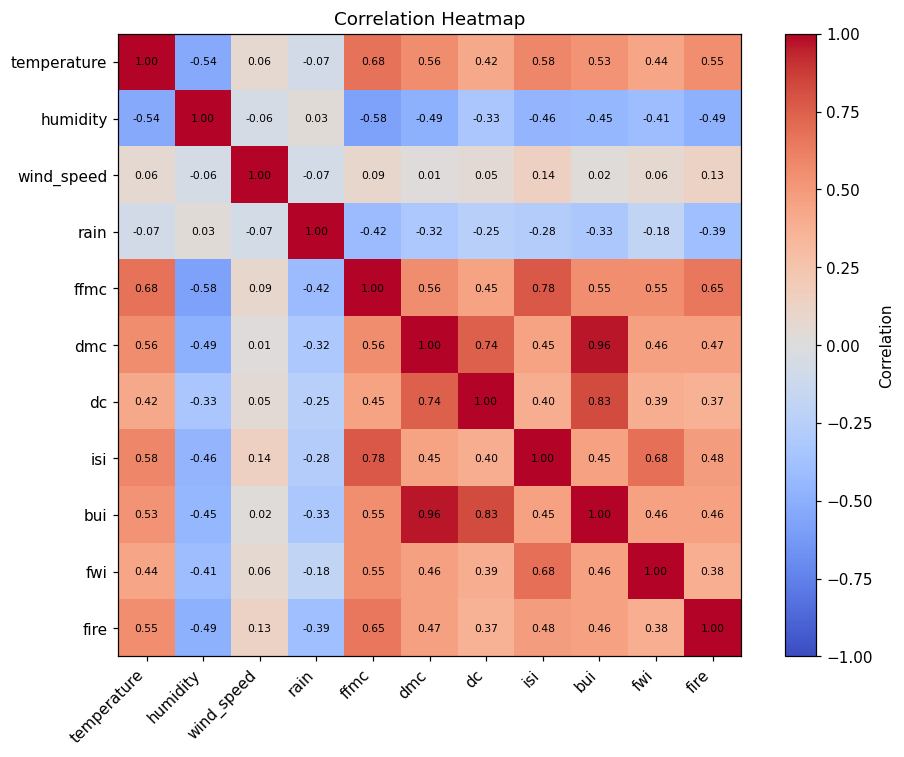

In [6]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Split Input and Output

In [7]:
X = df.drop(columns=["fire"])
y = df["fire"]

print("Input features:")
for feature in X.columns:
    print("-", feature)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Input features:
- temperature
- humidity
- wind_speed
- rain
- ffmc
- dmc
- dc
- isi
- bui
- fwi

X shape: (500, 10)
y shape: (500,)


## Train-Test Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (400, 10)
Testing data : (100, 10)


## Train Random Forest Classifier

In [9]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## Make Predictions

In [10]:
y_pred = rf_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": np.where(y_test.values[:10] == 1, "Fire", "No Fire"),
    "Predicted": np.where(y_pred[:10] == 1, "Fire", "No Fire")
})
print(comparison.to_string(index=False))

 Actual Predicted
   Fire   No Fire
   Fire      Fire
   Fire      Fire
No Fire   No Fire
No Fire   No Fire
   Fire   No Fire
No Fire      Fire
   Fire      Fire
   Fire      Fire
   Fire      Fire


## Model Evaluation

In [11]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"Accuracy in percentage: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Fire", "Fire"]))

Accuracy : 0.8300
Precision: 0.8727
Recall   : 0.8276
F1 Score : 0.8496
Accuracy in percentage: 83.00%

Classification Report:
              precision    recall  f1-score   support

     No Fire       0.78      0.83      0.80        42
        Fire       0.87      0.83      0.85        58

    accuracy                           0.83       100
   macro avg       0.83      0.83      0.83       100
weighted avg       0.83      0.83      0.83       100


## Confusion Matrix

[[35  7]
 [10 48]]


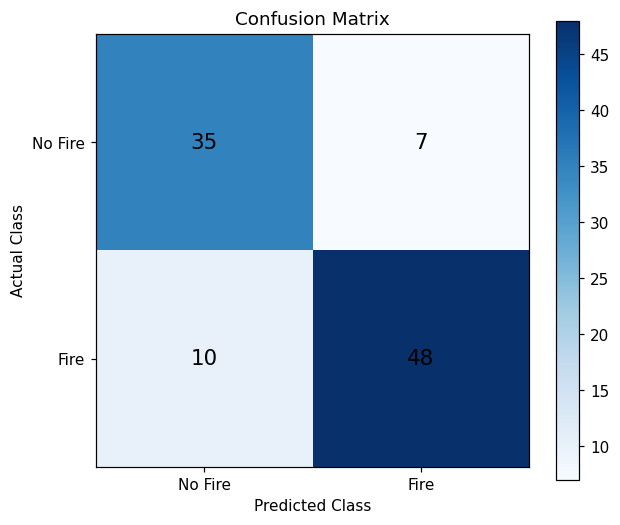

In [12]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1], ["No Fire", "Fire"])
plt.yticks([0, 1], ["No Fire", "Fire"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## Feature Importance

    Feature  Importance
       ffmc    0.287351
temperature    0.131480
   humidity    0.120967
       rain    0.092146
        isi    0.078148
        dmc    0.072084
        bui    0.070669
         dc    0.058022
        fwi    0.049285
 wind_speed    0.039848


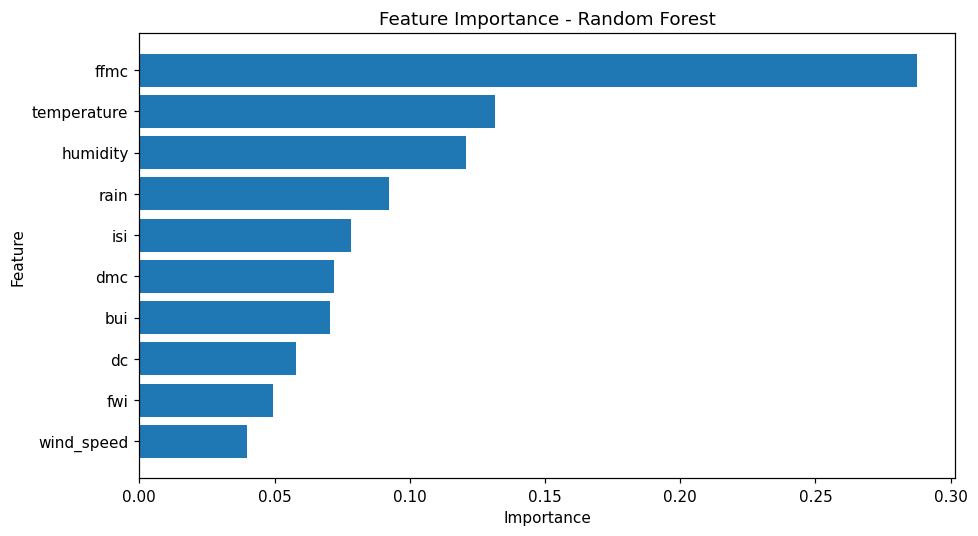

In [13]:
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=True)

print(importance_df.sort_values("Importance", ascending=False).round(6).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

## Predict Forest Fire Risk for New Conditions

In [14]:
def predict_fire_risk(temperature, humidity, wind_speed, rain,
                      ffmc, dmc, dc, isi, bui, fwi):
    area = pd.DataFrame([{
        "temperature": temperature,
        "humidity": humidity,
        "wind_speed": wind_speed,
        "rain": rain,
        "ffmc": ffmc,
        "dmc": dmc,
        "dc": dc,
        "isi": isi,
        "bui": bui,
        "fwi": fwi
    }])

    probability = float(rf_model.predict_proba(area)[0][1]) * 100

    if probability >= 70:
        level = "High Risk"
    elif probability >= 40:
        level = "Moderate Risk"
    else:
        level = "Low Risk"

    return round(probability, 2), level


# Hot, dry and windy day with no rain
prob, level = predict_fire_risk(
    temperature=38, humidity=45, wind_speed=20, rain=0.0,
    ffmc=90, dmc=45, dc=180, isi=4.5, bui=45, fwi=3.5
)
print("Fire Probability (%):", prob)
print("Fire Risk Level:", level)

# Cool, humid day with rain
prob, level = predict_fire_risk(
    temperature=25, humidity=85, wind_speed=10, rain=6.0,
    ffmc=60, dmc=8, dc=30, isi=0.3, bui=9, fwi=0.1
)
print("\nFire Probability (%):", prob)
print("Fire Risk Level:", level)

Fire Probability (%): 98.67
Fire Risk Level: High Risk

Fire Probability (%): 1.67
Fire Risk Level: Low Risk


## Save Trained Model

In [15]:
joblib.dump(rf_model, "forest_fire_random_forest.joblib")
print("Model saved successfully!")

Model saved successfully!
